# 01 Study area & AOI

**Study area:** Kandy, Kegalle, Nuwara Eliya, Ratnapura districts (central highlands,
the districts named in NBRO's Landslide Early Warning bulletins as active risk areas).

**Output:** `data/processed/aoi.gpkg` - a small GeoPackage, safe to reopen in every
subsequent notebook without ever loading a full raster or country-scale dataset.

**Dataset:** get district (and ideally DS division) boundaries into
`data/raw/`. - HDX- Datasets — Admin Boundaries (`data.humdata.org`)

In [3]:
import sys
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

sys.path.append("../src")
from landslide_lk import geo_utils

DATA_RAW = Path("../data/raw")
DATA_PROCESSED = Path("../data/processed")
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

## Load admin boundaries

In [ ]:
boundaries_path = DATA_RAW / "lka_admin_boundaries.gdb"
print(f"Expected boundaries at: {boundaries_path.resolve()}")
print(f"Exists: {boundaries_path.exists()}")
gpd.list_layers(boundaries_path)

,name,geometry_type
0,lka_admin0,MultiPolygon
1,lka_admin1,MultiPolygon
2,lka_admin2,MultiPolygon
3,lka_admin3,MultiPolygon
4,lka_admin4,MultiPolygon
5,lka_adminlines,MultiLineString
6,lka_adminpoints,Point


In [ ]:
#Checking the district level bounadries
admin2 = gpd.read_file(boundaries_path, layer="lka_admin2")
print(admin2.columns.tolist())
admin2.head()
admin2

['adm2_name', 'adm2_name1', 'adm2_name2', 'adm2_name3', 'adm2_pcode', 'adm1_name', 'adm1_name1', 'adm1_name2', 'adm1_name3', 'adm1_pcode', 'adm0_name', 'adm0_name1', 'adm0_name2', 'adm0_name3', 'adm0_pcode', 'valid_on', 'valid_to', 'area_sqkm', 'version', 'lang', 'lang1', 'lang2', 'lang3', 'center_lat', 'center_lon', 'geometry']


,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,...,valid_to,area_sqkm,version,lang,lang1,lang2,lang3,center_lat,center_lon,geometry
0,Colombo,කොළඹ දිස්ත්‍රික්ක,கொழும்பு மாவட்டம்,None,LK11,Western,බස්නාහිර පළාත,மேல் மாகாணம்,None,LK1,...,NaT,688.165915,v03,en,si,ta,None,6.848237,80.028636,"MULTIPOLYGON (((80.1793 6.97758, 80.17943 6.97..."
1,Gampaha,ගම්පහ දිස්ත්‍රික්,கம்பஹா மாவட்டம்,None,LK12,Western,බස්නාහිර පළාත,மேல் மாகாணம்,None,LK1,...,NaT,1416.400307,v03,en,si,ta,None,7.118687,80.020932,"MULTIPOLYGON (((80.14887 7.31242, 80.14899 7.3..."
2,Kalutara,කඵතර දිස්ත්‍රික්ක,களுத்துறை மாவட்டம,None,LK13,Western,බස්නාහිර පළාත,மேல் மாகாணம்,None,LK1,...,NaT,1646.991201,v03,en,si,ta,None,6.575649,80.134521,"MULTIPOLYGON (((80.1777 6.81586, 80.17773 6.81..."
3,Kandy,මහනුවර දිස්ත්‍රික,கண்டி மாவட்டம்,None,LK21,Central,මධ්‍යම පළාත,மத்திய மாகாணம்,None,LK2,...,NaT,1927.685470,v03,en,si,ta,None,7.215025,80.640563,"MULTIPOLYGON (((80.97387 7.48841, 80.97387 7.4..."
4,Matale,මාතලේ දිස්ත්‍රික්,மாத்தளை மாவட்டம்,None,LK22,Central,මධ්‍යම පළාත,மத்திய மாகாணம்,None,LK2,...,NaT,2058.748385,v03,en,si,ta,None,7.697902,80.660335,"MULTIPOLYGON (((80.98847 7.72049, 80.98849 7.7..."
5,Nuwara Eliya,නුවරඑළිය දිස්ත්‍ර,நுவரேலியா மாவட்டம,None,LK23,Central,මධ්‍යම පළාත,மத்திய மாகாணம்,None,LK2,...,NaT,1744.814836,v03,en,si,ta,None,7.013277,80.757041,"MULTIPOLYGON (((80.94775 7.20021, 80.94638 7.1..."
6,Galle,ගාල්ල දිස්ත්‍රික්,காலி மாவட்டம்,None,LK31,Southern,දකුණු පළාත,தென் மாகாணம்,None,LK3,...,NaT,1613.488582,v03,en,si,ta,None,6.204173,80.230922,"MULTIPOLYGON (((80.38092 6.42611, 80.38093 6.4..."
7,Matara,මාතර දිස්ත්‍රික්ක,மாத்தறை மாவட்டம்,None,LK32,Southern,දකුණු පළාත,தென் மாகாணம்,None,LK3,...,NaT,1306.370019,v03,en,si,ta,None,6.158222,80.519407,"MULTIPOLYGON (((80.67073 6.30554, 80.67073 6.3..."
8,Hambantota,හම්බන්තොට දිස්ත්‍,அம்பாந்தோட்டை மாவ,None,LK33,Southern,දකුණු පළාත,தென் மாகாணம்,None,LK3,...,NaT,2625.064132,v03,en,si,ta,None,6.275909,81.177961,"MULTIPOLYGON (((81.70704 6.5107, 81.70699 6.51..."
9,Jaffna,යාපනය දිස්ත්‍රික්,யாழ்ப்பாணம் மாவட்,None,LK41,Northern,උතුරු පළාත,வட மாகாணம்,None,LK4,...,NaT,1091.238807,v03,en,si,ta,None,9.643950,79.908380,"MULTIPOLYGON (((80.62281 9.45883, 80.62272 9.4..."


## Filter to the four target districts

In [10]:
DISTRICT_COLUMN = "adm2_name"

TARGET_DISTRICTS = ["Kandy", "Kegalle", "Nuwara Eliya", "Ratnapura", "Badulla", "Kalutara"]

aoi = admin2[admin2[DISTRICT_COLUMN].isin(TARGET_DISTRICTS)].copy()

assert len(aoi) == len(TARGET_DISTRICTS), (
    f"Expected {len(TARGET_DISTRICTS)} districts, matched {len(aoi)} — "
    f"check exact spelling. Found: {sorted(admin2[DISTRICT_COLUMN].unique())}"
)
aoi

,adm2_name,adm2_name1,adm2_name2,adm2_name3,adm2_pcode,adm1_name,adm1_name1,adm1_name2,adm1_name3,adm1_pcode,...,valid_to,area_sqkm,version,lang,lang1,lang2,lang3,center_lat,center_lon,geometry
2,Kalutara,කඵතර දිස්ත්‍රික්ක,களுத்துறை மாவட்டம,None,LK13,Western,බස්නාහිර පළාත,மேல் மாகாணம்,None,LK1,...,NaT,1646.991201,v03,en,si,ta,None,6.575649,80.134521,"MULTIPOLYGON (((80.1777 6.81586, 80.17773 6.81..."
3,Kandy,මහනුවර දිස්ත්‍රික,கண்டி மாவட்டம்,None,LK21,Central,මධ්‍යම පළාත,மத்திய மாகாணம்,None,LK2,...,NaT,1927.685470,v03,en,si,ta,None,7.215025,80.640563,"MULTIPOLYGON (((80.97387 7.48841, 80.97387 7.4..."
5,Nuwara Eliya,නුවරඑළිය දිස්ත්‍ර,நுவரேலியா மாவட்டம,None,LK23,Central,මධ්‍යම පළාත,மத்திய மாகாணம்,None,LK2,...,NaT,1744.814836,v03,en,si,ta,None,7.013277,80.757041,"MULTIPOLYGON (((80.94775 7.20021, 80.94638 7.1..."
21,Badulla,බදුල්ල දිස්ත්‍රික,பதுளை மாவட்டம்,None,LK81,Uva,ඌව පළාත,ஊவா மாகாணம்,None,LK8,...,NaT,2871.955928,v03,en,si,ta,None,7.082017,81.088717,"MULTIPOLYGON (((81.2708 7.27796, 81.27063 7.27..."
23,Ratnapura,රත්නපුර දිස්ත්‍රි,இரத்தினபுரம் மாவட,None,LK91,Sabaragamuwa,සබරගමුව පළාත,சபரகமுவ மாகாணம்,None,LK9,...,NaT,3287.075750,v03,en,si,ta,None,6.579880,80.590001,"MULTIPOLYGON (((80.49512 6.83197, 80.49512 6.8..."
24,Kegalle,කෑගල්ල දිස්ත්‍රික,கேகாலை மாவட்டம்,None,LK92,Sabaragamuwa,සබරගමුව පළාත,சபரகமுவ மாகாணம்,None,LK9,...,NaT,1657.732092,v03,en,si,ta,None,7.112890,80.321454,"MULTIPOLYGON (((80.42118 7.35622, 80.42129 7.3..."


In [11]:
#confirm six districts total area looks sane
print(aoi[["adm2_name", "adm2_pcode", "area_sqkm"]])
print(f"Total AOI area: {aoi['area_sqkm'].sum():.0f} km²")

       adm2_name adm2_pcode    area_sqkm
2       Kalutara       LK13  1646.991201
3          Kandy       LK21  1927.685470
5   Nuwara Eliya       LK23  1744.814836
21       Badulla       LK81  2871.955928
23     Ratnapura       LK91  3287.075750
24       Kegalle       LK92  1657.732092
Total AOI area: 13136 km²



## Reproject and save

Standardize to UTM zone 44N (EPSG:32644) - Sri Lanka's local metric CRS, so
every later distance/area calculation (distance-to-river, slope, etc.) is in
real-world meters rather than degrees. This also matches the reprojection step
in prior Sri Lankan landslide studies for consistency.

In [12]:
aoi_utm = aoi.to_crs("EPSG:32644")
aoi_dissolved = aoi_utm.dissolve()

out_path = DATA_PROCESSED / "aoi.gpkg"
aoi_utm.to_file(out_path, layer="districts", driver="GPKG")
aoi_dissolved.to_file(out_path, layer="dissolved", driver="GPKG")
print(f"Saved: {out_path.resolve()}")

Saved: D:\PROJECTS\Landslide_prediction\data\processed\aoi.gpkg


## Quick visual sanity check

Confirming the AOI before moving on - a wrong CRS or a mis-spelled district name 

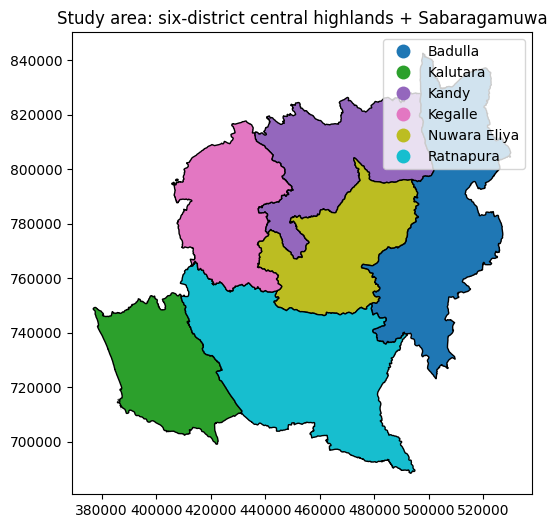

In [13]:
fig, ax = plt.subplots(figsize=(6, 6))
aoi_utm.plot(ax=ax, edgecolor="black", column="adm2_name", legend=True)
ax.set_title("Study area: six-district central highlands + Sabaragamuwa")
plt.show()

## Next

`notebooks/02_terrain.ipynb` will load only `data/processed/aoi.gpkg`
(a few KB)

Every later data-layer notebook (`02_terrain`, `03_climate`, `04_context`,
`05_labels`) should start by loading this AOI and clipping its own raw source
data to it via `geo_utils.clip_raster_to_aoi()` before doing anything else.